# Step 4: Regression & Classification on the Step 3 datasets
Uses `train.csv`, `val.csv`, `test.csv` from Step 3 (already encoded, no missing values, chronological split with purge gap).

**Task:** predict `Demand` (kWh) of a charging session *at the moment it starts*. `Duration` is not used, so there is no leakage.

- Regression target: `Demand`
- Classification target: `HighDemand` = Demand >= **training-set** median (same threshold applied to val and test)
- Models are fitted on **train**, compared on **val**, and the chosen model is scored **once on test**.
- Cross-validation uses `TimeSeriesSplit` (no shuffling).

Sections: 1 Load · 2 Visualisation · 3 Regression · 4 Classification · 5 Class imbalance · 6 SHAP · 7 LIME · 8 Summary

In [2]:
# %pip install xgboost lightgbm imbalanced-learn shap lime
RS = 42
import sys, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score, ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBRegressor, XGBClassifier
from lightgbm import LGBMRegressor, LGBMClassifier
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN
from imblearn.pipeline import Pipeline as ImbPipeline
# On Windows a broken optional pyspark install can crash shap's import (socketserver.UnixStreamServer error).
# Blocking pyspark is harmless: shap only needs it for Spark features we do not use.
sys.modules['pyspark'] = None
import shap
from lime.lime_tabular import LimeTabularExplainer
sns.set_theme(style='whitegrid')

## 1. Load the Step 3 datasets

In [3]:
import os
FOLDER = r"D:\HCL_PROJECTS\EV_Charging_Demand_Analysis Project-2"

train = pd.read_csv(os.path.join(FOLDER, 'train.csv'))
val   = pd.read_csv(os.path.join(FOLDER, 'val.csv'))
test  = pd.read_csv(os.path.join(FOLDER, 'test.csv'))

target = 'Demand'
DROP_MONTH = ['Month', 'Month_sin', 'Month_cos']     # one year of data: val/test months are unseen in train, and they add nothing
FEATURES = [c for c in train.columns if c != target and c not in DROP_MONTH]

X_train, y_train = train[FEATURES], train[target]
X_val,   y_val   = val[FEATURES],   val[target]
X_test,  y_test  = test[FEATURES],  test[target]

# Classification label: threshold from TRAIN only
THR = y_train.median()
yc_train, yc_val, yc_test = [(y >= THR).astype(int) for y in (y_train, y_val, y_test)]

print('Shapes:', X_train.shape, X_val.shape, X_test.shape)
print('Missing values:', int(train.isna().sum().sum() + val.isna().sum().sum() + test.isna().sum().sum()))
print(f'Median threshold (train) = {THR:.2f} kWh | High-demand share  train {yc_train.mean():.3f}  val {yc_val.mean():.3f}  test {yc_test.mean():.3f}')
X_train.describe().T.round(2).head(20)

Shapes: (50391, 35) (10776, 35) (10805, 35)
Missing values: 0
Median threshold (train) = 14.37 kWh | High-demand share  train 0.500  val 0.494  test 0.487


,count,mean,std,min,25%,50%,75%,max
Hour,50391.0,14.65,5.04,0.00,11.00,16.00,19.00,23.00
Day,50391.0,15.63,8.83,1.00,8.00,16.00,23.00,31.00
DayOfWeek,50391.0,2.92,1.95,0.00,1.00,3.00,5.00,6.00
IsWeekend,50391.0,0.26,0.44,0.00,0.00,0.00,1.00,1.00
Hour_sin,50391.0,-0.33,0.68,-1.00,-0.97,-0.71,0.26,1.00
Hour_cos,50391.0,-0.24,0.61,-1.00,-0.71,-0.26,0.26,1.00
DoW_sin,50391.0,0.03,0.70,-0.97,-0.78,0.00,0.78,0.97
DoW_cos,50391.0,-0.03,0.71,-0.90,-0.90,-0.22,0.62,1.00
ChargerType,50391.0,0.19,0.39,0.00,0.00,0.00,0.00,1.00
ChargerCompany,50391.0,0.64,0.48,0.00,0.00,1.00,1.00,1.00


## 2. Data visualisation
The Step 3 files are already encoded, so location is recovered from the one-hot columns for plotting only.

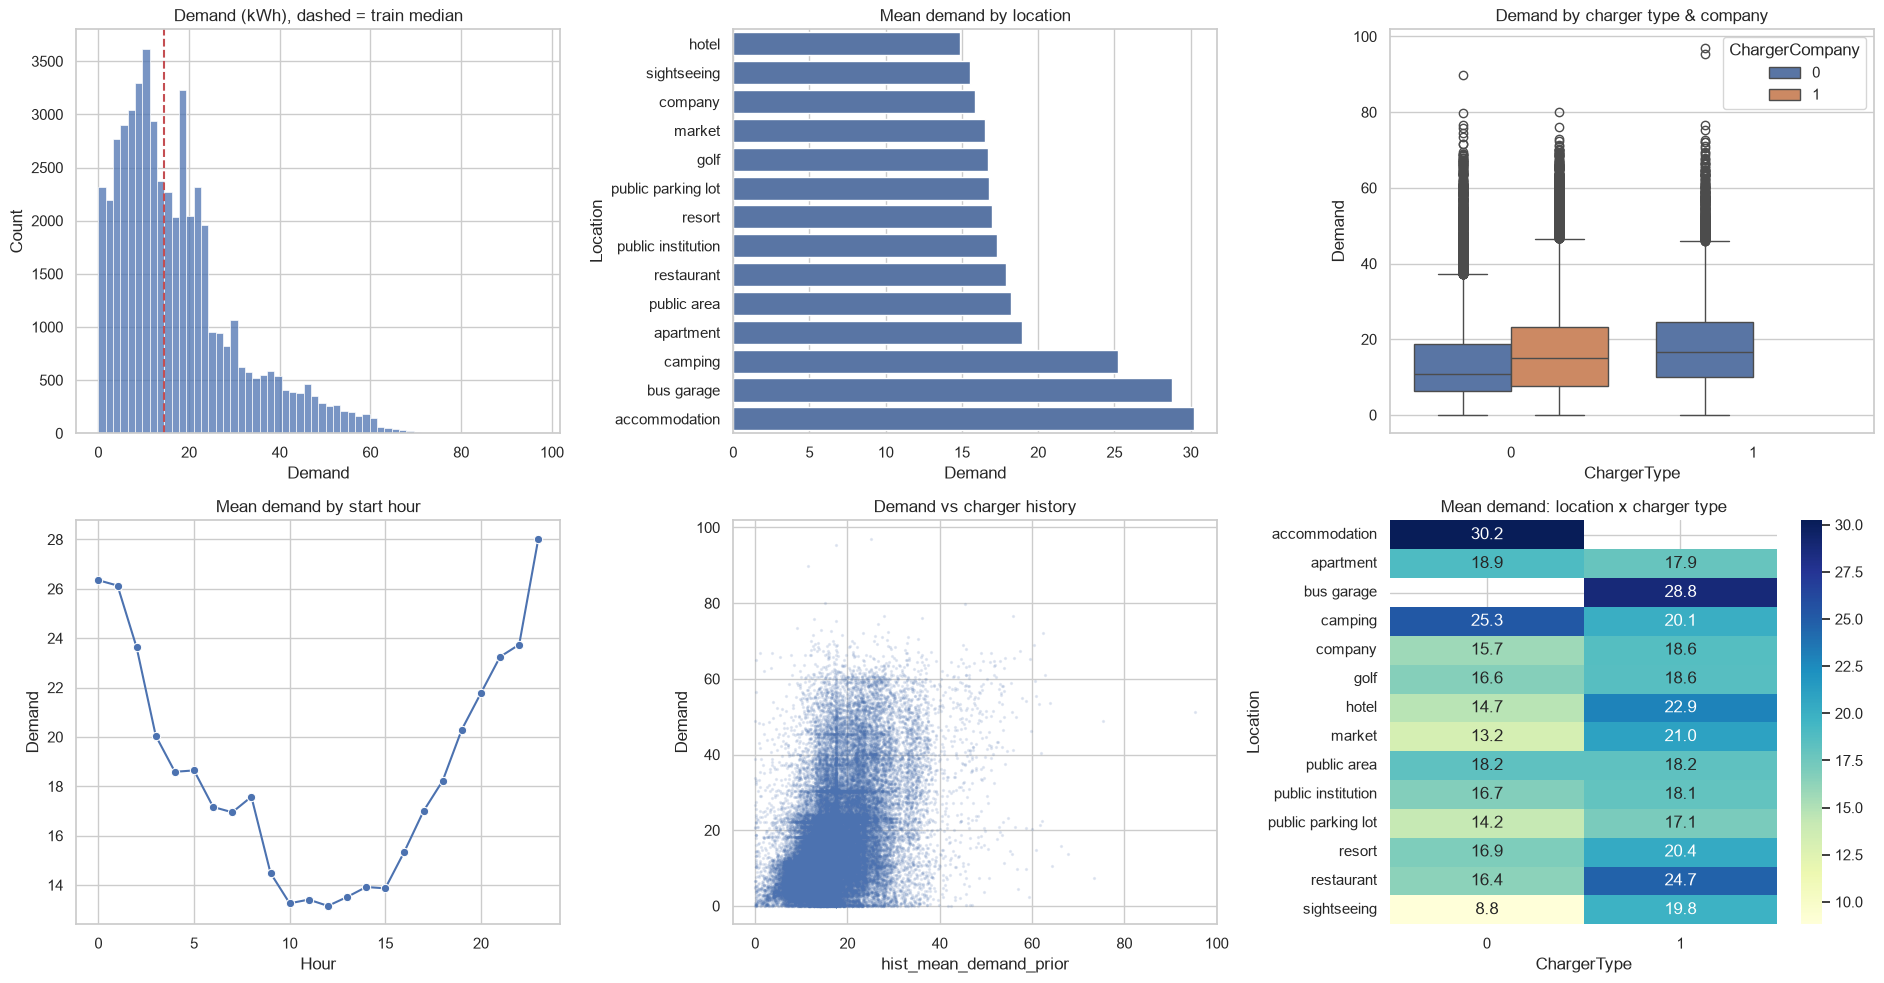

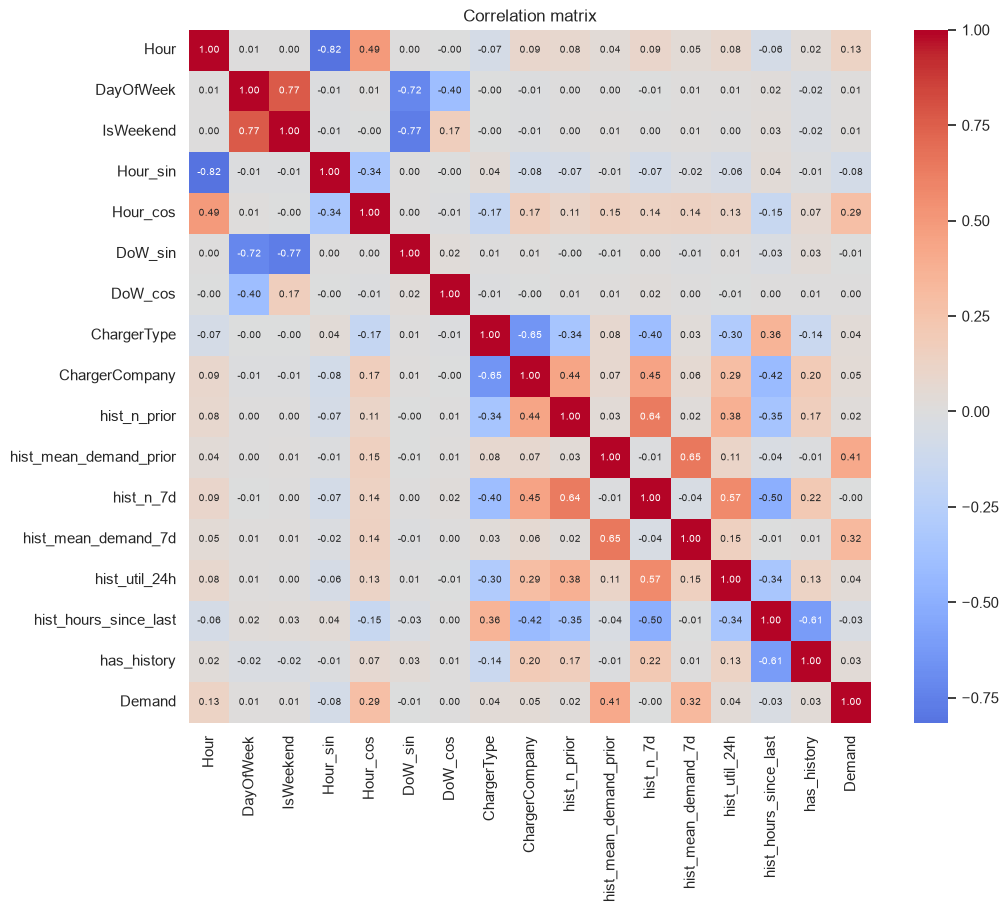

In [4]:
loc_cols = [c for c in train.columns if c.startswith('Location_')]
tod_cols = [c for c in train.columns if c.startswith('TimeOfDay_')]
viz = train.copy()
viz['Location'] = viz[loc_cols].idxmax(axis=1).str.replace('Location_', '')
fig, ax = plt.subplots(2, 3, figsize=(19, 10))
sns.histplot(y_train, bins=60, ax=ax[0,0]); ax[0,0].axvline(THR, color='r', ls='--'); ax[0,0].set_title('Demand (kWh), dashed = train median')
order = viz.groupby('Location')['Demand'].mean().sort_values().index
sns.barplot(data=viz, y='Location', x='Demand', order=order, errorbar=None, ax=ax[0,1]); ax[0,1].set_title('Mean demand by location')
sns.boxplot(data=viz, x='ChargerType', y='Demand', hue='ChargerCompany', ax=ax[0,2]); ax[0,2].set_title('Demand by charger type & company')
sns.lineplot(data=viz.groupby('Hour')['Demand'].mean().reset_index(), x='Hour', y='Demand', marker='o', ax=ax[1,0]); ax[1,0].set_title('Mean demand by start hour')
ax[1,1].scatter(viz['hist_mean_demand_prior'], viz['Demand'], s=2, alpha=.12); ax[1,1].set_xlabel('hist_mean_demand_prior'); ax[1,1].set_ylabel('Demand'); ax[1,1].set_title('Demand vs charger history')
sns.heatmap(viz.pivot_table(index='Location', columns='ChargerType', values='Demand', aggfunc='mean'), annot=True, fmt='.1f', cmap='YlGnBu', ax=ax[1,2]); ax[1,2].set_title('Mean demand: location x charger type')
plt.tight_layout(); plt.show()

num_view = [c for c in FEATURES if c not in loc_cols + tod_cols and c not in ('Day',)]
plt.figure(figsize=(11,9)); sns.heatmap(train[num_view+[target]].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size':7}); plt.title('Correlation matrix'); plt.show()

## 3. Regression: model comparison
Common setup: scaling only for the linear model, `TimeSeriesSplit` CV on **train**, then validation and test scores. Select the model on **validation**; test is reported for the final check.

In [5]:
tscv = TimeSeriesSplit(n_splits=3)
def scaled(m): return Pipeline([('s', StandardScaler()), ('m', m)])

reg_models = {
 'Linear Regression': scaled(LinearRegression()),
 'Decision Tree': DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=RS),
 'Random Forest': RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=RS),
 'Gradient Boosting': GradientBoostingRegressor(n_estimators=150, subsample=0.5, max_depth=4, random_state=RS),
 'XGBoost': XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=.8, colsample_bytree=.8, n_jobs=-1, random_state=RS),
 'LightGBM': LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, subsample=.8, subsample_freq=1, colsample_bytree=.8, n_jobs=-1, random_state=RS, verbose=-1),
}
def rscore(m, X, y):
    p = m.predict(X); return dict(MAE=mean_absolute_error(y,p), RMSE=np.sqrt(mean_squared_error(y,p)), R2=r2_score(y,p))

rows, reg_fit = [], {}
base = np.full(len(y_val), y_train.mean())
rows.append({'Model':'Mean baseline','CV_R2':np.nan,'val_MAE':mean_absolute_error(y_val,base),'val_RMSE':np.sqrt(mean_squared_error(y_val,base)),'val_R2':r2_score(y_val,base),
             'test_MAE':mean_absolute_error(y_test,np.full(len(y_test),y_train.mean())),'test_R2':r2_score(y_test,np.full(len(y_test),y_train.mean()))})
for n, m in reg_models.items():
    cv = cross_val_score(clone(m), X_train, y_train, cv=tscv, scoring='r2', n_jobs=1).mean()
    m = clone(m).fit(X_train, y_train); reg_fit[n] = m
    v, t = rscore(m, X_val, y_val), rscore(m, X_test, y_test)
    rows.append({'Model':n,'CV_R2':cv,'val_MAE':v['MAE'],'val_RMSE':v['RMSE'],'val_R2':v['R2'],'test_MAE':t['MAE'],'test_R2':t['R2']})
reg_res = pd.DataFrame(rows).set_index('Model')
best_reg = reg_res.drop('Mean baseline')['val_RMSE'].idxmin()
print('Best regressor (lowest validation RMSE):', best_reg)
reg_res.round(3)

Best regressor (lowest validation RMSE): XGBoost


,CV_R2,val_MAE,val_RMSE,val_R2,test_MAE,test_R2
Model,,,,,,
Mean baseline,NaN,10.841,13.995,-0.001,10.735,-0.001
Linear Regression,0.230,9.175,12.229,0.236,9.129,0.225
Decision Tree,0.199,9.096,12.291,0.228,9.275,0.161
Random Forest,0.252,8.951,12.064,0.256,9.050,0.211
Gradient Boosting,0.225,8.995,12.095,0.252,8.992,0.224
XGBoost,0.227,8.887,12.034,0.260,8.966,0.219
LightGBM,0.249,8.902,12.047,0.258,8.935,0.223


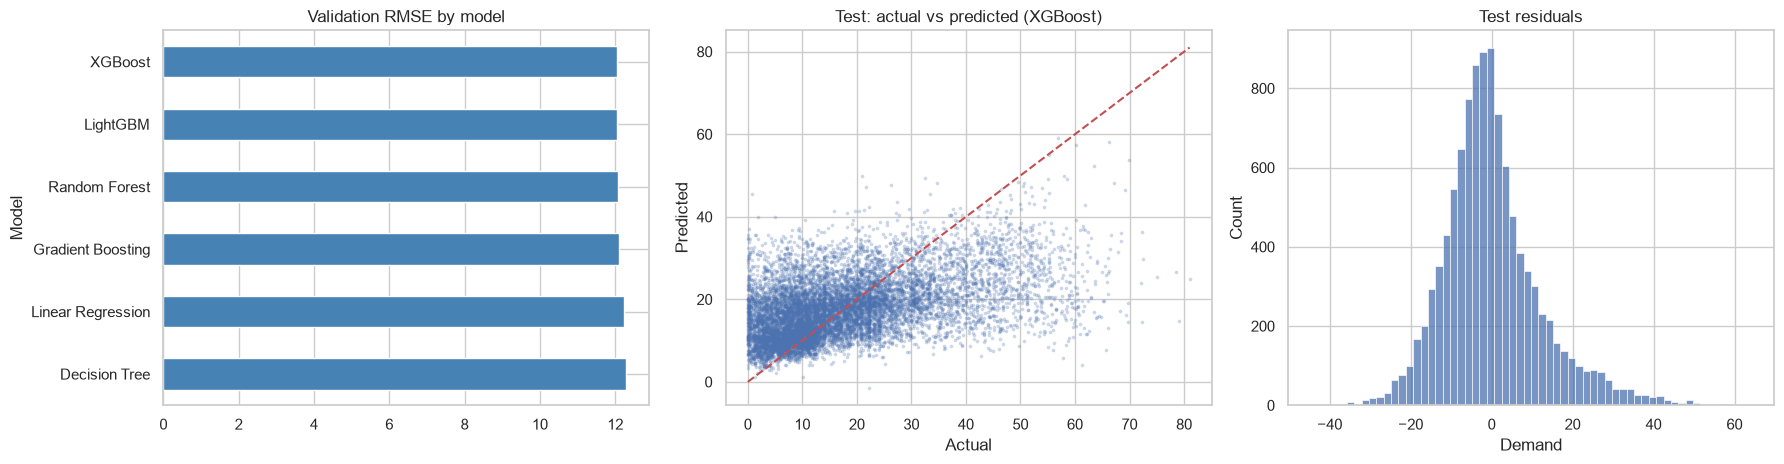

In [6]:
pr = reg_fit[best_reg].predict(X_test)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
reg_res.drop('Mean baseline')['val_RMSE'].sort_values(ascending=False).plot.barh(ax=ax[0], color='steelblue'); ax[0].set_title('Validation RMSE by model')
ax[1].scatter(y_test, pr, s=3, alpha=.2); ax[1].plot([0, y_test.max()], [0, y_test.max()], 'r--'); ax[1].set_title(f'Test: actual vs predicted ({best_reg})'); ax[1].set_xlabel('Actual'); ax[1].set_ylabel('Predicted')
sns.histplot(y_test-pr, bins=60, ax=ax[2]); ax[2].set_title('Test residuals'); plt.tight_layout(); plt.show()

## 4. Classification: model comparison
Target: `HighDemand` (Demand >= train median). Selected on validation ROC-AUC, then checked on test.

In [7]:
clf_models = {
 'Logistic Regression': scaled(LogisticRegression(max_iter=2000, random_state=RS)),
 'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=RS),
 'Random Forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=RS),
 'KNN': scaled(KNeighborsClassifier(n_neighbors=25, n_jobs=-1)),
 'SVM': scaled(SVC(kernel='rbf', random_state=RS)),
 'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=.8, colsample_bytree=.8, n_jobs=-1, random_state=RS, eval_metric='logloss'),
 'LightGBM': LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=.8, subsample_freq=1, colsample_bytree=.8, n_jobs=-1, random_state=RS, verbose=-1),
}
SVM_N = 12000   # SVM is slow: train on the most recent 12k training rows
def cscore(p, X, y):
    pr = p.predict(X); s = p.predict_proba(X)[:,1] if hasattr(p, 'predict_proba') else p.decision_function(X)
    return dict(Accuracy=accuracy_score(y,pr), Precision=precision_score(y,pr,zero_division=0), Recall=recall_score(y,pr),
                F1=f1_score(y,pr), ROC_AUC=roc_auc_score(y,s), PR_AUC=average_precision_score(y,s))
rows, clf_fit = [], {}
for n, m in clf_models.items():
    m = clone(m)
    if n == 'SVM': m.fit(X_train.iloc[-SVM_N:], yc_train.iloc[-SVM_N:])
    else: m.fit(X_train, yc_train)
    clf_fit[n] = m
    v, t = cscore(m, X_val, yc_val), cscore(m, X_test, yc_test)
    rows.append({'Model':n, **{f'val_{k}':x for k,x in v.items()}, 'test_F1':t['F1'], 'test_ROC_AUC':t['ROC_AUC'], 'test_Accuracy':t['Accuracy']})
clf_res = pd.DataFrame(rows).set_index('Model')
best_clf = clf_res['val_ROC_AUC'].idxmax()
print('Best classifier (highest validation ROC-AUC):', best_clf)
clf_res.round(3)

Best classifier (highest validation ROC-AUC): Random Forest


,val_Accuracy,val_Precision,val_Recall,val_F1,val_ROC_AUC,val_PR_AUC,test_F1,test_ROC_AUC,test_Accuracy
Model,,,,,,,,,
Logistic Regression,0.687,0.677,0.701,0.689,0.757,0.734,0.677,0.743,0.675
Decision Tree,0.689,0.673,0.720,0.696,0.759,0.719,0.685,0.747,0.673
Random Forest,0.700,0.686,0.723,0.704,0.778,0.753,0.690,0.759,0.685
KNN,0.680,0.666,0.704,0.685,0.741,0.702,0.666,0.722,0.664
SVM,0.703,0.683,0.744,0.712,0.767,0.732,0.692,0.752,0.684
XGBoost,0.702,0.688,0.726,0.706,0.777,0.753,0.696,0.760,0.686
LightGBM,0.700,0.684,0.729,0.706,0.775,0.750,0.698,0.760,0.690


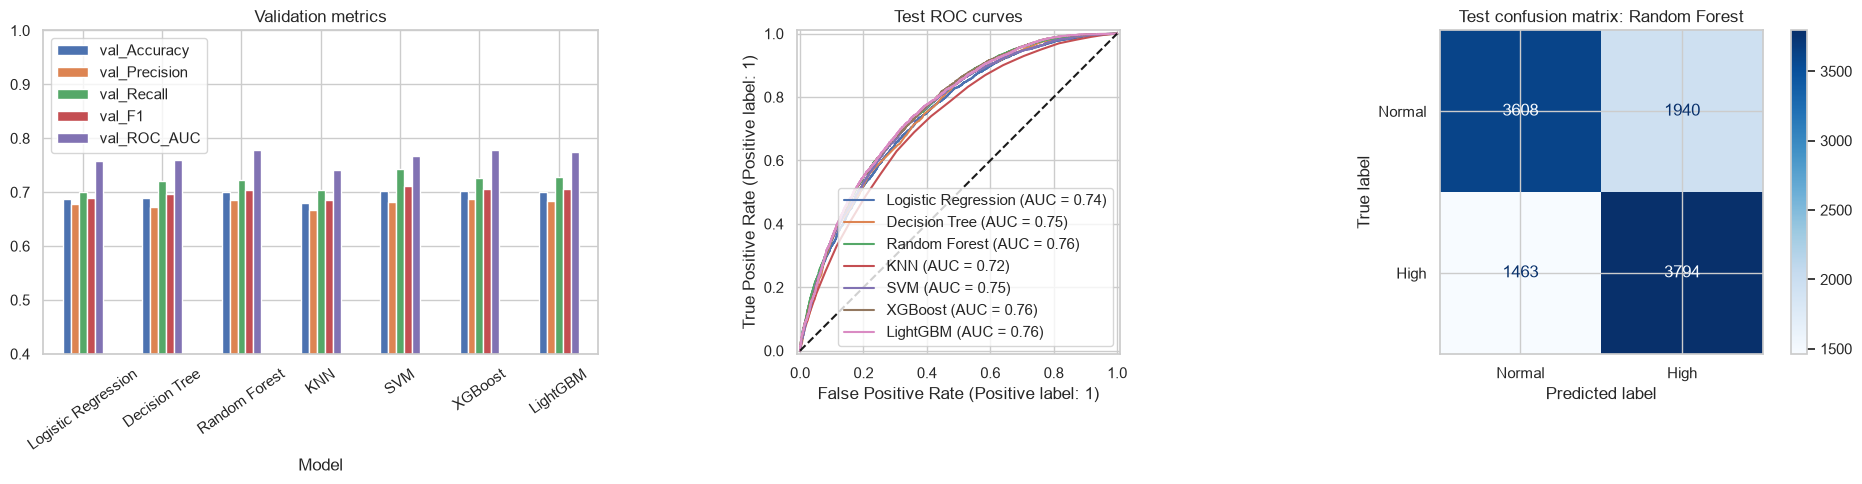

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
clf_res[['val_Accuracy','val_Precision','val_Recall','val_F1','val_ROC_AUC']].plot.bar(ax=ax[0], rot=35); ax[0].set_ylim(.4, 1); ax[0].set_title('Validation metrics')
for n, p in clf_fit.items(): RocCurveDisplay.from_estimator(p, X_test, yc_test, name=n, ax=ax[1])
ax[1].plot([0,1],[0,1],'k--'); ax[1].set_title('Test ROC curves')
ConfusionMatrixDisplay.from_predictions(yc_test, clf_fit[best_clf].predict(X_test), display_labels=['Normal','High'], cmap='Blues', ax=ax[2]); ax[2].set_title(f'Test confusion matrix: {best_clf}')
plt.tight_layout(); plt.show()

## 5. Handling class imbalance
**Step 1: check.** The median split is balanced by construction.

In [9]:
vc = yc_train.value_counts().sort_index()
print(pd.DataFrame({'count': vc, 'share': (vc/len(yc_train)).round(4)}).rename(index={0:'Normal', 1:'High'}))
print(f'Majority:minority = {vc.max()/vc.min():.3f} -> balanced, resampling not required for the median target.')

        count   share
Demand               
Normal  25187  0.4998
High    25204  0.5002
Majority:minority = 1.001 -> balanced, resampling not required for the median target.


**Step 2: demonstrate on a genuinely imbalanced target.** *Very high demand* = Demand >= 90th percentile **of train** (about 10% of sessions). Samplers run **inside the training pipeline only**; validation and test stay untouched. Compare Recall, F1 and PR-AUC rather than accuracy.

In [10]:
thr90 = y_train.quantile(.9)
y90_tr, y90_va, y90_te = [(y >= thr90).astype(int) for y in (y_train, y_val, y_test)]
print(f'90th percentile (train) = {thr90:.2f} kWh | positive share  train {y90_tr.mean():.3f}  val {y90_va.mean():.3f}  test {y90_te.mean():.3f}')
base_models = {'Logistic Regression': (True, LogisticRegression(max_iter=2000, random_state=RS)),
               'Random Forest': (False, RandomForestClassifier(n_estimators=100, min_samples_leaf=5, max_samples=0.5, n_jobs=-1, random_state=RS)),
               'LightGBM': (False, LGBMClassifier(n_estimators=300, learning_rate=0.05, subsample=.8, subsample_freq=1, colsample_bytree=.8, n_jobs=-1, random_state=RS, verbose=-1))}
strategies = {'None': None, 'class_weight=balanced': 'cw', 'Random Oversampling': RandomOverSampler(random_state=RS), 'SMOTE': SMOTE(random_state=RS), 'ADASYN': ADASYN(random_state=RS)}
rows = []
for mn, (sc, est) in base_models.items():
    for sn, smp in strategies.items():
        e = clone(est); steps = [('sc', StandardScaler())] if sc else []
        if smp == 'cw': e.set_params(class_weight='balanced')
        elif smp is not None: steps.append(('s', smp))
        pipe = ImbPipeline(steps + [('m', e)]).fit(X_train, y90_tr)
        rows.append({'Model': mn, 'Strategy': sn, **cscore(pipe, X_val, y90_va)})
imb = pd.DataFrame(rows).set_index(['Model', 'Strategy']); imb.round(4)

90th percentile (train) = 37.17 kWh | positive share  train 0.101  val 0.114  test 0.108


Accuracy  Precision  Recall  \
Model               Strategy                                             
Logistic Regression None                     0.8882     0.5585  0.0856   
                    class_weight=balanced    0.7234     0.2545  0.7408   
                    Random Oversampling      0.7251     0.2553  0.7376   
                    SMOTE                    0.7232     0.2538  0.7376   
                    ADASYN                   0.7008     0.2411  0.7579   
Random Forest       None                     0.8900     0.6591  0.0709   
                    class_weight=balanced    0.7917     0.3056  0.6520   
                    Random Oversampling      0.8296     0.3460  0.5575   
                    SMOTE                    0.8895     0.5383  0.2062   
                    ADASYN                   0.8892     0.5422  0.1728   
LightGBM            None                     0.8907     0.6099  0.1108   
                    class_weight=balanced    0.7726     0.2902  0.6895   
                    Random Oversampling      0.7753     0.2899  0.6716   
                    SMOTE                    0.8906     0.5945  0.1231   
                    ADASYN                   0.8912     0.6078  0.1263   

                                               F1  ROC_AUC  PR_AUC  
Model               Strategy                                        
Logistic Regression None                   0.1484   0.7999  0.3641  
                    class_weight=balanced  0.3788   0.8017  0.3609  
                    Random Oversampling    0.3793   0.8016  0.3609  
                    SMOTE                  0.3776   0.7994  0.3591  
                    ADASYN                 0.3659   0.7974  0.3575  
Random Forest       None                   0.1280   0.8158  0.3940  
                    class_weight=balanced  0.4161   0.8213  0.3904  
                    Random Oversampling    0.4270   0.8196  0.3902  
                    SMOTE                  0.2982   0.8141  0.3785  
                    ADASYN                 0.2621   0.8146  0.3752  
LightGBM            None                   0.1876   0.8161  0.3902  
                    class_weight=balanced  0.4085   0.8160  0.3900  
                    Random Oversampling    0.4050   0.8159  0.3853  
                    SMOTE                  0.2039   0.8185  0.3897  
                    ADASYN                 0.2092   0.8166  0.3871

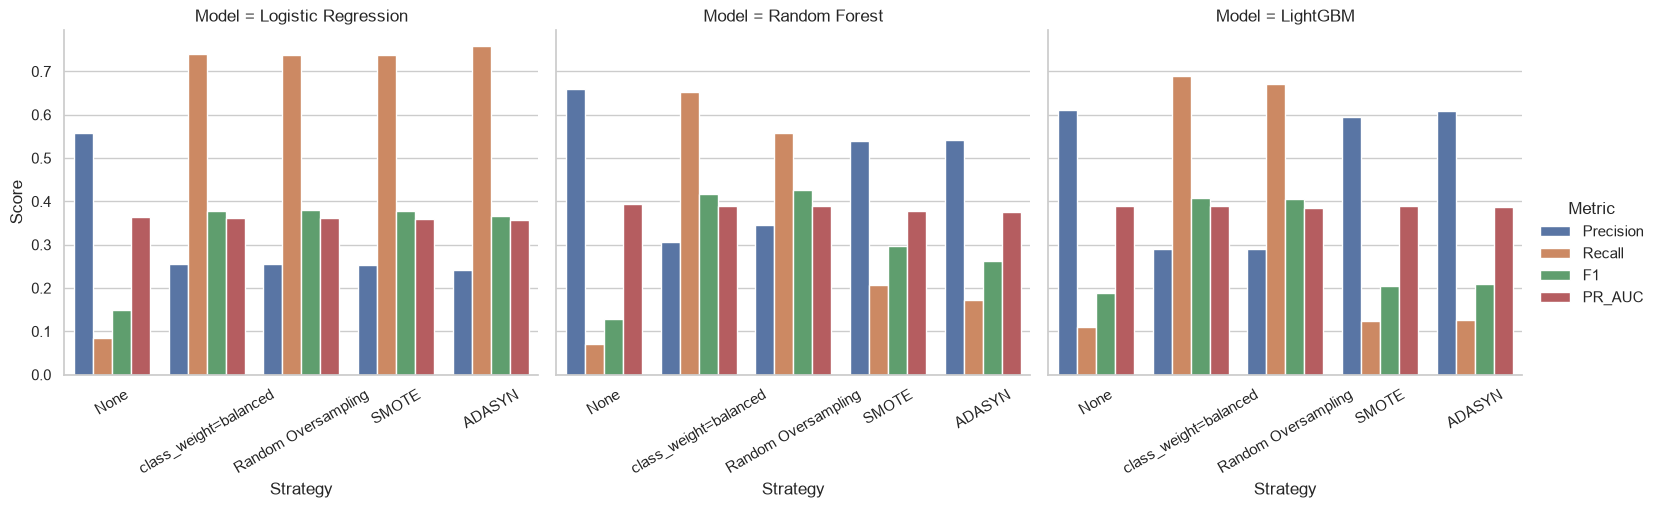

In [11]:
g = imb.reset_index().melt(id_vars=['Model','Strategy'], value_vars=['Precision','Recall','F1','PR_AUC'], var_name='Metric', value_name='Score')
sns.catplot(data=g, x='Strategy', y='Score', hue='Metric', col='Model', kind='bar', height=4.5, aspect=1.15).set_xticklabels(rotation=30); plt.show()

**Reading:** oversampling and class weights trade precision for recall (more true very-high sessions found, more false alarms). Ranking quality (ROC-AUC / PR-AUC) changes little. Choose the strategy by the cost of a missed high-demand session versus a false alarm.

## 6. Explainable AI: SHAP
Global and local explanations for the best regressor and best classifier. Both are tree models in practice; if the best is not tree-based, SHAP falls back to the best tree model.

In [ ]:
TREE = ['Decision Tree','Random Forest','Gradient Boosting','XGBoost','LightGBM']
shap_reg = best_reg if best_reg in TREE else reg_res.drop('Mean baseline').loc[TREE,'val_RMSE'].idxmin()
shap_clf = best_clf if best_clf in TREE else clf_res.loc[[t for t in TREE if t in clf_res.index],'val_ROC_AUC'].idxmax()
reg_m, clf_m = reg_fit[shap_reg], clf_fit[shap_clf]
Xs = X_val.sample(2000, random_state=RS)
exp_r, exp_c = shap.TreeExplainer(reg_m), shap.TreeExplainer(clf_m)
sv_r = exp_r.shap_values(Xs); sv_c = exp_c.shap_values(Xs)
if isinstance(sv_c, list): sv_c = sv_c[1]
if np.ndim(sv_c) == 3: sv_c = sv_c[:, :, 1]
print('Regression:', shap_reg, '| Classification:', shap_clf)

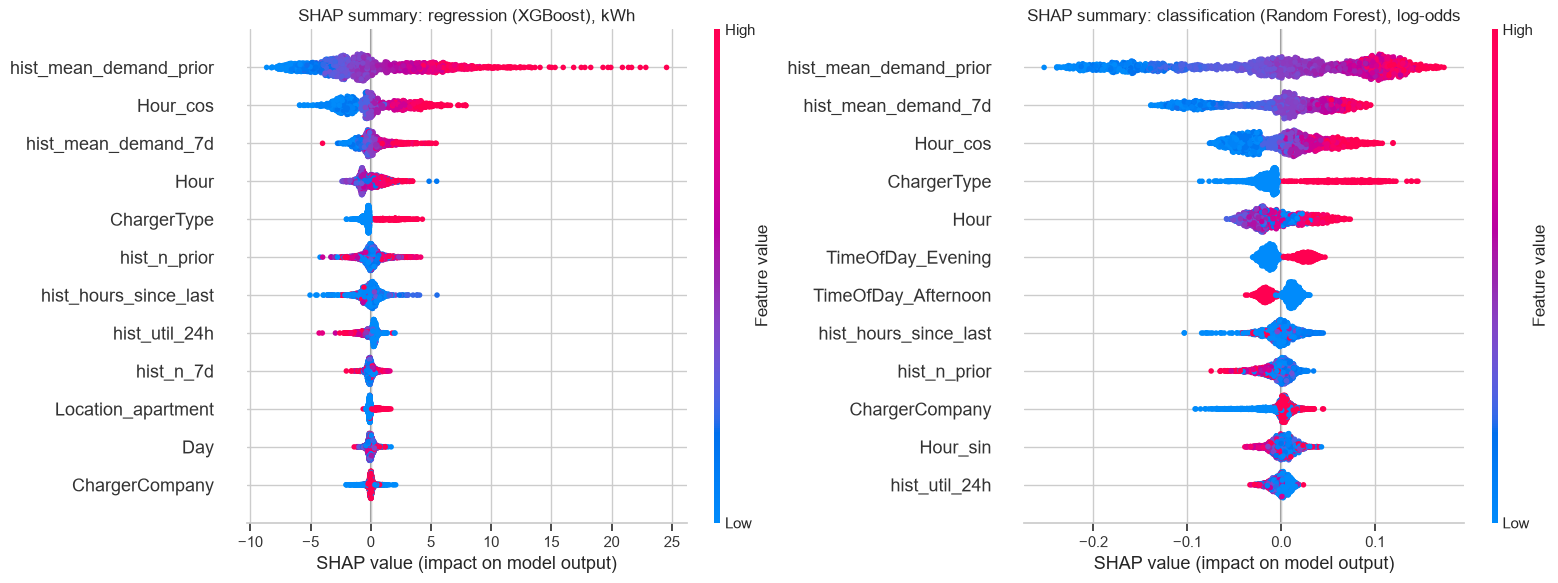

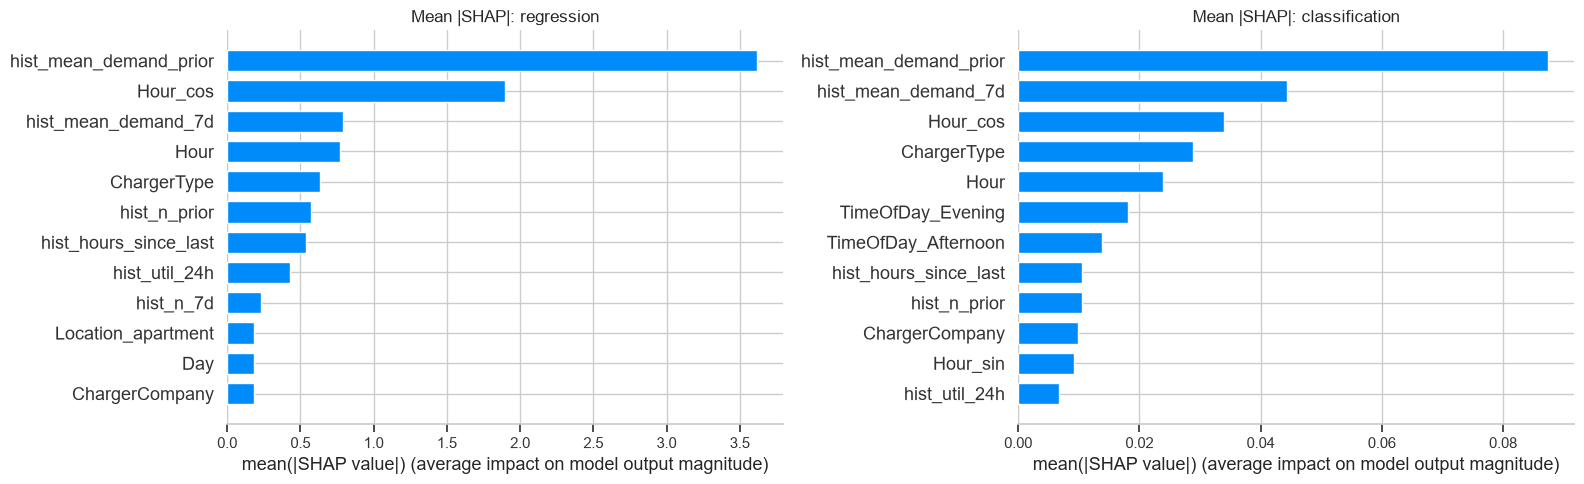

In [13]:
plt.figure(figsize=(16, 6))
plt.subplot(1,2,1); shap.summary_plot(sv_r, Xs, show=False, max_display=12, plot_size=None); plt.title(f'SHAP summary: regression ({shap_reg}), kWh')
plt.subplot(1,2,2); shap.summary_plot(sv_c, Xs, show=False, max_display=12, plot_size=None); plt.title(f'SHAP summary: classification ({shap_clf}), log-odds')
plt.tight_layout(); plt.show()
plt.figure(figsize=(16, 5))
plt.subplot(1,2,1); shap.summary_plot(sv_r, Xs, plot_type='bar', show=False, max_display=12, plot_size=None); plt.title('Mean |SHAP|: regression')
plt.subplot(1,2,2); shap.summary_plot(sv_c, Xs, plot_type='bar', show=False, max_display=12, plot_size=None); plt.title('Mean |SHAP|: classification')
plt.tight_layout(); plt.show()

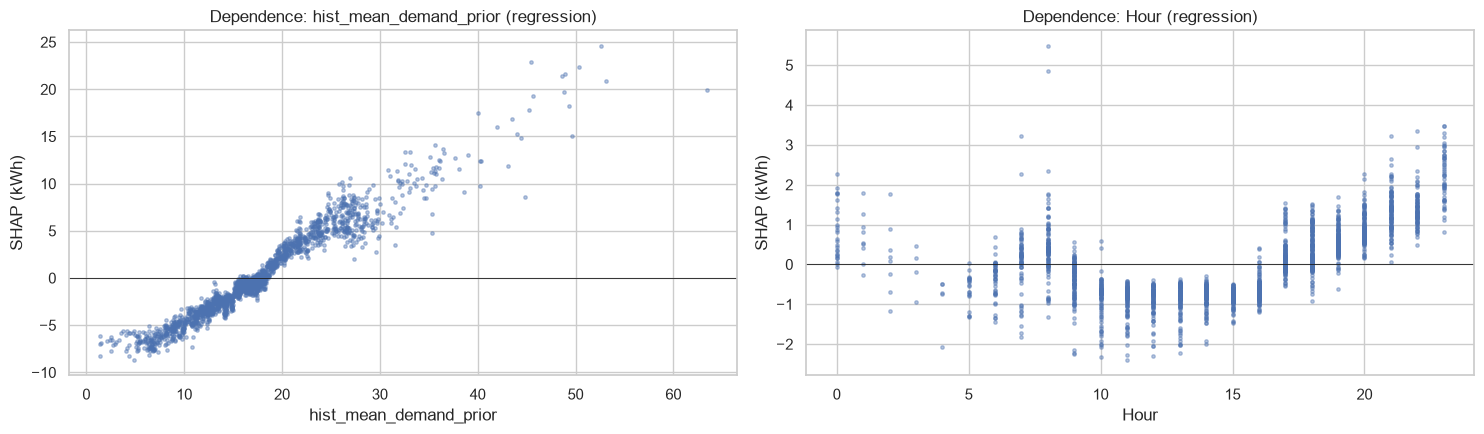

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, f in zip(ax, ['hist_mean_demand_prior', 'Hour']):
    a.scatter(Xs[f], sv_r[:, Xs.columns.get_loc(f)], s=6, alpha=.4); a.axhline(0, color='k', lw=.6); a.set_xlabel(f); a.set_ylabel('SHAP (kWh)'); a.set_title(f'Dependence: {f} (regression)')
plt.tight_layout(); plt.show()

**Local explanations:** one high-demand and one normal-demand session from the test set, explained for the classifier.

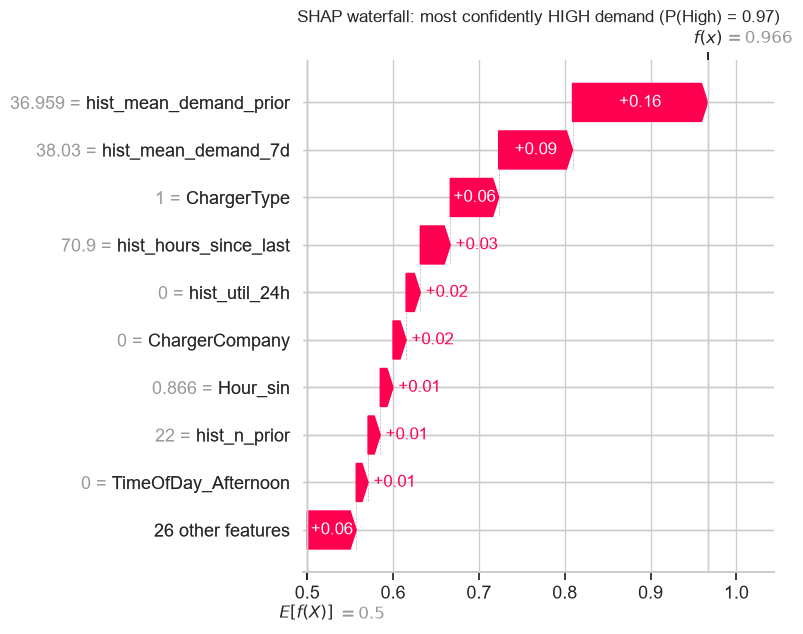

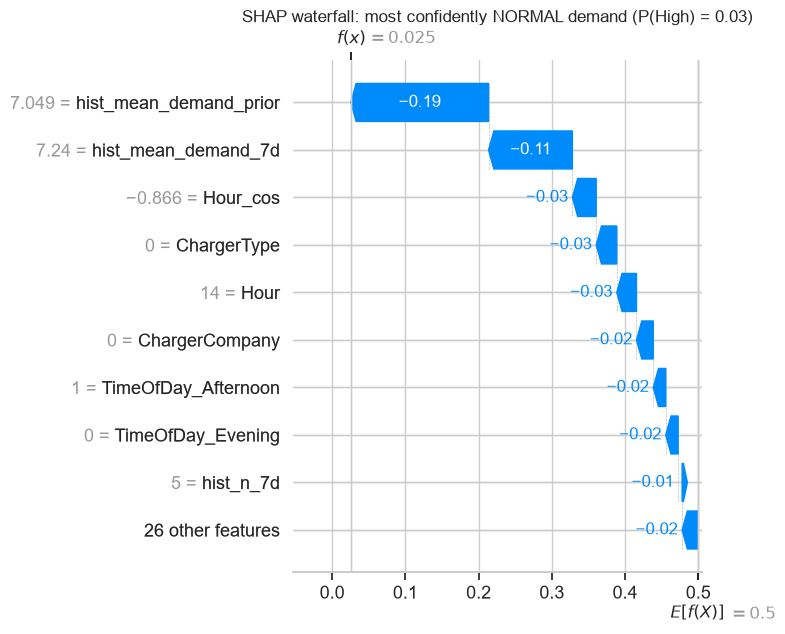

In [20]:
pc = clf_m.predict_proba(X_test)[:, 1]
i_high, i_norm = int(np.argmax(pc)), int(np.argmin(pc))
sv_t = exp_c.shap_values(X_test.iloc[[i_high, i_norm]])
if isinstance(sv_t, list): sv_t = sv_t[1]
if np.ndim(sv_t) == 3: sv_t = sv_t[:, :, 1]
bv = exp_c.expected_value; bv = float(np.ravel(bv)[-1])
for k, (idx, lab) in enumerate([(i_high, 'most confidently HIGH demand'), (i_norm, 'most confidently NORMAL demand')]):
    shap.plots.waterfall(shap.Explanation(sv_t[k], bv, X_test.iloc[idx].values, feature_names=list(X_test.columns)), max_display=10, show=False)
    plt.title(f'SHAP waterfall: {lab} (P(High) = {pc[idx]:.2f})'); plt.tight_layout(); plt.show()

## 7. Explainable AI: LIME
Local linear approximation around the same two sessions, and one typical regression prediction.

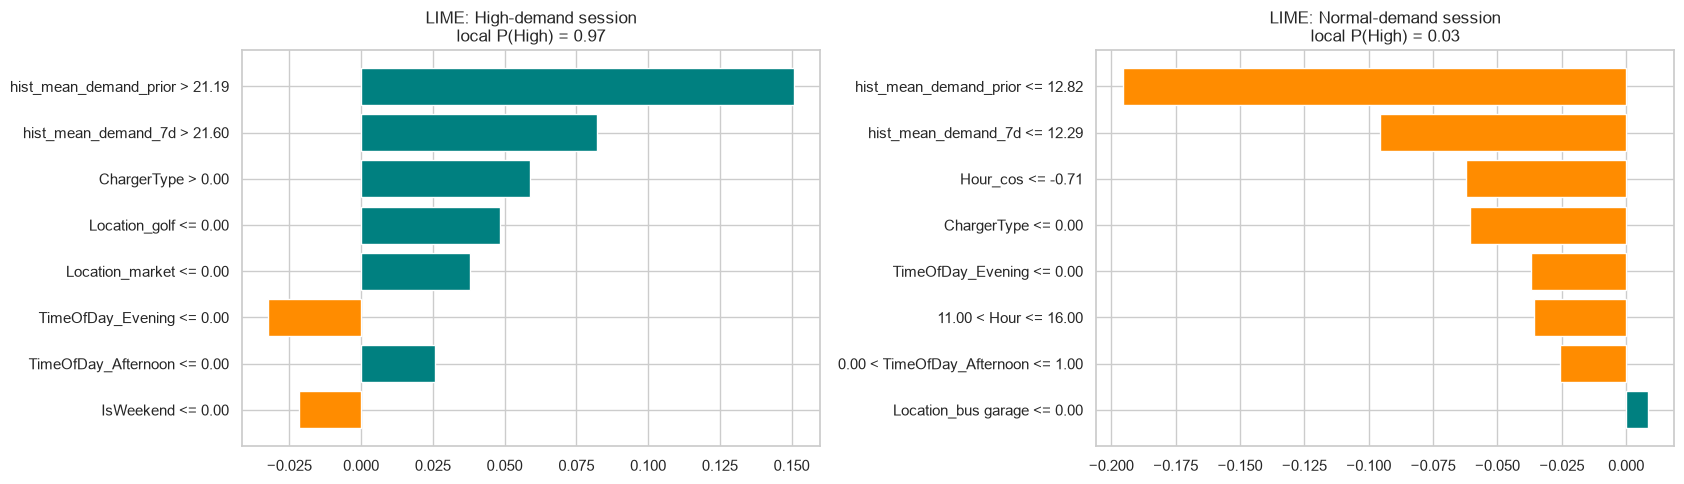

In [21]:
bg = X_train.sample(2000, random_state=RS)
lime_c = LimeTabularExplainer(bg.values, feature_names=list(bg.columns), class_names=['Normal','High'], mode='classification', discretize_continuous=True, random_state=RS)
fn_c = lambda a: clf_m.predict_proba(pd.DataFrame(a, columns=bg.columns))
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
for a, (idx, lab) in zip(ax, [(i_high, 'High-demand session'), (i_norm, 'Normal-demand session')]):
    e = lime_c.explain_instance(X_test.iloc[idx].values, fn_c, num_features=8, num_samples=2000)
    d = pd.DataFrame(e.as_list(), columns=['Condition', 'Weight']).iloc[::-1]
    a.barh(d['Condition'], d['Weight'], color=['teal' if w > 0 else 'darkorange' for w in d['Weight']]); a.set_title(f'LIME: {lab}\nlocal P(High) = {e.predict_proba[1]:.2f}')
plt.tight_layout(); plt.show()

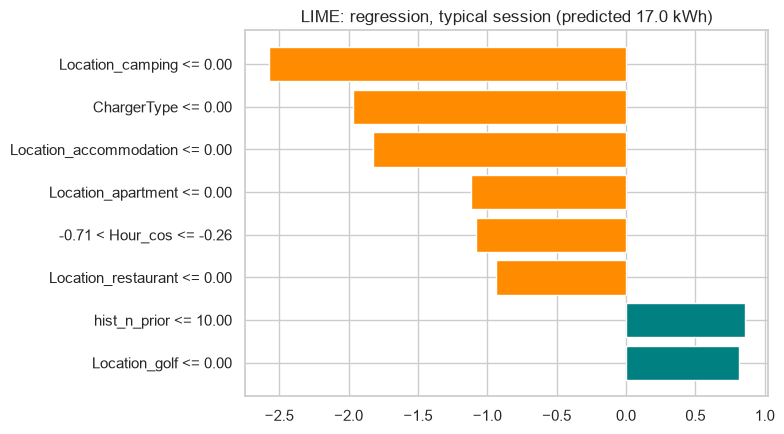

In [22]:
lime_r = LimeTabularExplainer(bg.values, feature_names=list(bg.columns), mode='regression', discretize_continuous=True, random_state=RS)
fn_r = lambda a: reg_m.predict(pd.DataFrame(a, columns=bg.columns))
j = int(np.argsort(reg_m.predict(X_test))[len(X_test)//2])      # a typical (median-prediction) session
e = lime_r.explain_instance(X_test.iloc[j].values, fn_r, num_features=8, num_samples=2000)
d = pd.DataFrame(e.as_list(), columns=['Condition','Weight']).iloc[::-1]
plt.figure(figsize=(8,4.5)); plt.barh(d['Condition'], d['Weight'], color=['teal' if w > 0 else 'darkorange' for w in d['Weight']])
plt.title(f'LIME: regression, typical session (predicted {reg_m.predict(X_test.iloc[[j]])[0]:.1f} kWh)'); plt.tight_layout(); plt.show()

### SHAP vs LIME
- **SHAP**: consistent global and local explanations that add up to the prediction; fast for tree models.
- **LIME**: local linear approximation, easy to read for one session, varies a little between runs, no global view.

## 8. Summary

In [23]:
from IPython.display import Markdown
shap_top = pd.Series(np.abs(sv_c).mean(0), index=Xs.columns).sort_values(ascending=False).head(3).index.tolist()
r, b = reg_res.loc[best_reg], clf_res.loc[best_clf]
Markdown(f'''
- **Regression:** best on validation = **{best_reg}**. Test: MAE {r.test_MAE:.2f} kWh, R2 {r.test_R2:.3f} (mean baseline R2 {reg_res.loc['Mean baseline','test_R2']:.3f}).
- **Classification:** best on validation = **{best_clf}**. Test: Accuracy {b.test_Accuracy:.3f}, F1 {b.test_F1:.3f}, ROC-AUC {b.test_ROC_AUC:.3f}.
- **Class imbalance:** the median target is balanced (50/50). On a 10% positive target, resampling and class weights raise recall at the cost of precision, with little change in ROC/PR-AUC.
- **Explainability:** SHAP ranks **{shap_top[0]}**, **{shap_top[1]}**, **{shap_top[2]}** as the main drivers of high-demand sessions.
- **Interpretation:** these are plug-in-time forecasts (no `Duration`), so scores are modest by design; including `Duration` would score higher but only by leaking the outcome.
''')


- **Regression:** best on validation = **XGBoost**. Test: MAE 8.97 kWh, R2 0.219 (mean baseline R2 -0.001).
- **Classification:** best on validation = **Random Forest**. Test: Accuracy 0.685, F1 0.690, ROC-AUC 0.759.
- **Class imbalance:** the median target is balanced (50/50). On a 10% positive target, resampling and class weights raise recall at the cost of precision, with little change in ROC/PR-AUC.
- **Explainability:** SHAP ranks **hist_mean_demand_prior**, **hist_mean_demand_7d**, **Hour_cos** as the main drivers of high-demand sessions.
- **Interpretation:** these are plug-in-time forecasts (no `Duration`), so scores are modest by design; including `Duration` would score higher but only by leaking the outcome.
